# Аналіз результатів експериментів

Зошит обробляє результати `petri experiments all` з теки `results/` і готує рисунки та таблиці для звіту:

| Розділ звіту | Що тут рахується | Рисунки / таблиці |
|---|---|---|
| 3.7 Верифікація | множини маркірувань проти дерева, тупики, мертві переходи, середні маркірування; ймовірність тупику філософів | `tables/verification-*.csv` |
| 4.2 Швидкодія | серії A, B, C; регресія в log-log; стала частина такту; пришвидшення | `figures/4.2-*.png`, `tables/4.2-*.csv` |
| 4.3 Досяжні маркірування | частка знайдених маркірувань, запуски до насичення, криві насичення | `figures/4.3-*.png`, `tables/4.3-*.csv` |
| 4.4 Активність | частки спрацювань і рівні активності | `tables/4.4-*.csv` |
| 5.2 Пропозиція | час серій з перебором та інкрементальним пошуком, пришвидшення | `figures/5.2-proposal.png`, `tables/5.2-proposal.csv` |

Довірча ймовірність β = 0,95; похибки - за нерівністю Чебишева, як і в застосунку.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
RESULTS = ROOT / "results"
FIGURES = ROOT / "report" / "figures"
TABLES = ROOT / "report" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

BETA = 0.95

# Validated categorical slots (light mode); every series also differs by marker and line style for print.
STYLE = {
    "naive": dict(color="#257de0", marker="o", linestyle="-", label="перебір"),
    "incremental": dict(color="#f47230", marker="s", linestyle="--", label="інкрементальний"),
}
SLOTS = ["#257de0", "#f47230", "#00b894"]
MARKERS = ["o", "s", "^"]
LINES = ["-", "--", ":"]

plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e0e0e0",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#666666",
    "axes.labelcolor": "#191919",
    "xtick.color": "#666666",
    "ytick.color": "#666666",
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "legend.frameon": False,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")


def chebyshev_error(variance, n):
    return np.sqrt(variance / ((1 - BETA) * n))


print(RESULTS)
print((RESULTS / "environment.txt").read_text())

/home/andrii/University/kpi-7-semester/Моделювання дискретних систем/coursework/results
Date:              2026-11-26 15:00:30 +0200
Processor:         12th Gen Intel(R) Core(TM) i5-12450H
Logical CPUs:      12
Physical memory:   15650 MiB
Operating system:  Linux 7.0.0-43-generic (amd64)
Java:              OpenJDK 64-Bit Server VM 25.0.5+8-LTS (Eclipse Adoptium)
Maximum heap:      4096 MiB



/home/andrii/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 4.2 Швидкодія

Умови одного експерименту: L = 100 000 тактів на запуск; перед кожною точкою 5 запусків прогріву, які не записуються
(щоб JIT-компілятор встиг скомпілювати код під цю мережу); далі 20 вимірюваних запусків. Точка - медіана
20 вимірювань, тож поодинокі збурення (збирач сміття, ОС) на неї майже не впливають.

### Серії A, B, C: регресія в log-log

Для кожної точки - медіана 20 вимірювань часу такту. Розкид вимірювань (від мінімуму до максимуму) - у середньому
1,6-5,3 % від медіани, на логарифмічній осі він менший за маркер, тому на графіках не показаний. Залежність від розміру шукається у вигляді
t = c·x^k, тобто log t = log c + k·log x (метод найменших квадратів). Нахил k порівнюється з теоретичною оцінкою.
Додатково наведено «локальні» нахили між сусідніми точками: вони показують, де залежність змінюється.

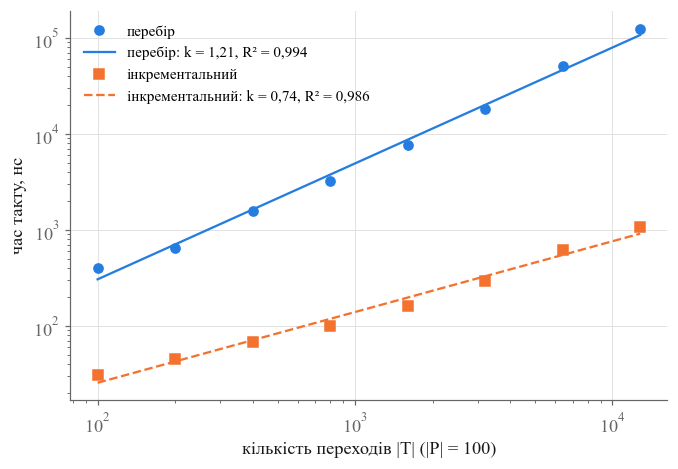

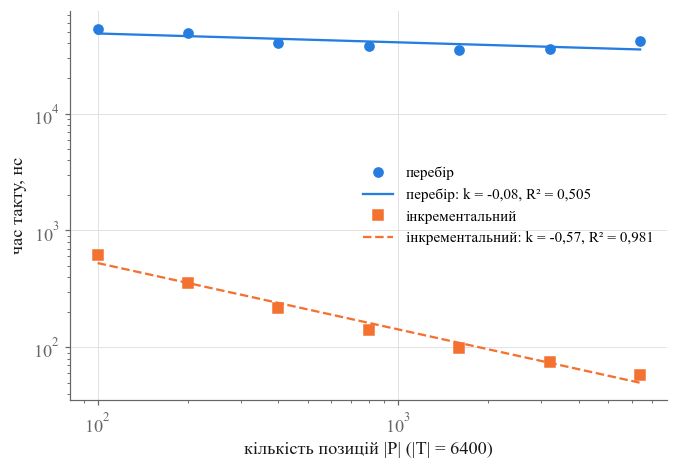

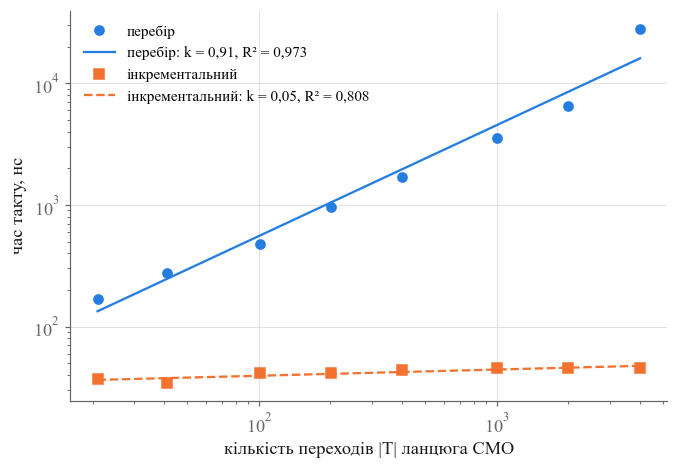

,series,finder,k,k_theory,r2
0,A,перебір,1.207,1,0.994
1,A,інкрементальний,0.737,1,0.986
2,B,перебір,-0.076,0,0.505
3,B,інкрементальний,-0.567,-1,0.981
4,C,перебір,0.912,1,0.973
5,C,інкрементальний,0.051,0,0.808


In [2]:
SERIES = {
    "A": dict(x="transitions", xlabel="кількість переходів |T| (|P| = 100)", theory={"naive": 1, "incremental": 1}),
    "B": dict(x="places", xlabel="кількість позицій |P| (|T| = 6400)", theory={"naive": 0, "incremental": -1}),
    "C": dict(x="transitions", xlabel="кількість переходів |T| ланцюга СМО", theory={"naive": 1, "incremental": 0}),
}

summaries = {s: pd.read_csv(RESULTS / "benchmark" / f"series-{s.lower()}" / "summary.csv") for s in SERIES}


def loglog_fit(x, y):
    lx, ly = np.log10(x), np.log10(y)
    k, c = np.polyfit(lx, ly, 1)
    residual = ly - (c + k * lx)
    r2 = 1 - np.sum(residual ** 2) / np.sum((ly - ly.mean()) ** 2)
    return k, 10 ** c, r2


slope_rows, local_rows = [], []
for name, spec in SERIES.items():
    data = summaries[name]
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for finder, style in STYLE.items():
        part = data[data["finder"] == finder].sort_values(spec["x"])
        x = part[spec["x"]].to_numpy()
        y = part["median_ns_per_tick"].to_numpy()
        k, c, r2 = loglog_fit(x, y)
        slope_rows.append(dict(series=name, finder=style["label"], k=k, k_theory=spec["theory"][finder], r2=r2))
        for i in range(1, len(x)):
            local_rows.append(dict(series=name, finder=style["label"], x_from=x[i - 1], x_to=x[i],
                                   local_k=np.log(y[i] / y[i - 1]) / np.log(x[i] / x[i - 1])))
        ax.plot(x, y, color=style["color"], marker=style["marker"], linestyle="none", label=style["label"])
        grid = np.geomspace(x.min(), x.max(), 50)
        ax.plot(grid, c * grid ** k, color=style["color"], linestyle=style["linestyle"], linewidth=1.5,
                label=f'{style["label"]}: k = {k:.2f}, R² = {r2:.3f}'.replace(".", ","))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(spec["xlabel"])
    ax.set_ylabel("час такту, нс")
    ax.legend(fontsize=10)
    save(fig, f"4.2-series-{name.lower()}")
    plt.show()

slopes = pd.DataFrame(slope_rows)
slopes.to_csv(TABLES / "4.2-slopes.csv", index=False)
local = pd.DataFrame(local_rows)
local.to_csv(TABLES / "4.2-local-slopes.csv", index=False)
slopes.round(3)

In [3]:
local.pivot_table(index=["series", "x_from", "x_to"], columns="finder", values="local_k").round(2)

finder               перебір  інкрементальний
series x_from x_to                           
A      100    200       0.71             0.57
       200    400       1.27             0.59
       400    800       1.03             0.55
       800    1600      1.24             0.70
       1600   3200      1.26             0.86
       3200   6400      1.50             1.07
       6400   12800     1.29             0.80
B      100    200      -0.12            -0.80
       200    400      -0.29            -0.71
       400    800      -0.10            -0.62
       800    1600     -0.10            -0.52
       1600   3200      0.04            -0.40
       3200   6400      0.23            -0.39
C      21     41        0.73            -0.10
       41     101       0.62             0.21
       101    201       1.00            -0.01
       201    401       0.84             0.10
       401    1001      0.81             0.03
       1001   2001      0.87            -0.00
       2001   4001      2.11             0.02

### Стала частина такту

Крок складається зі сталої частини (вибір випадкового переходу, запуск, оновлення маркірування) і частини, що росте
з розміром. Лінійна модель t = a + b·u, де u - величина з теоретичної оцінки: для перебору u = T, для інкрементального
пошуку в машині станів u = T/P (скільки переходів читають з однієї позиції). Вільний член a - оцінка сталої частини.

In [4]:
def linear_fit(u, y):
    b, a = np.polyfit(u, y, 1)
    residual = y - (a + b * u)
    return a, b, 1 - np.sum(residual ** 2) / np.sum((y - y.mean()) ** 2)


# Series and the variable of the theoretical estimate: T for the naive finder, T/P for the incremental one.
LINEAR_FITS = [("A", "naive", "T"), ("C", "naive", "T"), ("A", "incremental", "T/P"), ("B", "incremental", "T/P")]
linear_rows = []
for name, finder, u_name in LINEAR_FITS:
    part = summaries[name][summaries[name]["finder"] == finder]
    u = part["transitions"] if u_name == "T" else part["transitions"] / part["places"]
    a, b, r2 = linear_fit(u.to_numpy(float), part["median_ns_per_tick"].to_numpy())
    linear_rows.append(dict(series=name, finder=STYLE[finder]["label"], u=u_name, a_ns=a, b_ns=b, r2=r2))
linear = pd.DataFrame(linear_rows)
linear.to_csv(TABLES / "4.2-linear.csv", index=False)
linear.round(3)

,series,finder,u,a_ns,b_ns,r2
0,A,перебір,T,-5117.707,9.720,0.986
1,C,перебір,T,-1124.046,6.539,0.926
2,A,інкрементальний,T/P,34.086,8.312,0.996
3,B,інкрементальний,T/P,63.944,8.802,0.997


### Висновки щодо серій A, B, C

**Інкрементальний пошук** відповідає теоретичній оцінці O(T/P) для машини станів і O(1) для ланцюга СМО:

* серія C: нахил k ≈ 0,05 (теорія 0) - час такту майже сталий, 37-46 нс при зростанні T у 190 разів;
* серії A і B: нахили в log-log (0,74 і −0,57) менші за модулем від теоретичних (1 і −1), бо такт має сталу частину,
  яка не залежить від розміру. Лінійна модель t = a + b·T/P описує обидві серії з R² ≈ 0,996-0,997, а коефіцієнти
  b (≈ 8,3 і 8,8 нс на перехід, що читає зі зміненої позиції) майже збігаються - це та сама залежність, виміряна двома
  незалежними серіями. Стала частина a ≈ 34-64 нс. Локальні нахили серії A наближаються до 1 зі зростанням T/P,
  коли змінна частина починає переважати сталу.

**Перебір** відповідає оцінці O(T) лише наближено:

* серія A: нахил 1,21, локальні нахили зростають від ≈ 1 до 1,5 - час росте швидше за лінійний (від'ємний вільний
  член лінійної моделі - ознака опуклої залежності). Причина - ієрархія пам'яті: зі зростанням T об'єкти переходів,
  дуг і позицій перестають уміщатися в кеші процесора, і перевірка одного переходу дорожчає;
* серія C: нахил 0,91 до T = 2001, але між T = 2001 і T = 4001 локальний нахил 2,11 - той самий ефект кешу;
* серія B: нахил ≈ −0,08 (теорія 0): кількість дуг стала, тож і час майже сталий; R² тут малий, бо майже немає
  залежності, яку можна було б пояснити.

Отже, теоретичні оцінки кількості операцій підтверджено, а відхилення від них пояснюються сталою частиною такту
(інкрементальний пошук) і кешем процесора (перебір на великих мережах).

### Пришвидшення інкрементального пошуку

Пришвидшення = медіана часу такту перебором / медіана часу такту інкрементальним пошуком.
Число для найбільшого ланцюга СМО - «пробний запуск і оцінка поліпшення» для розділу 5. Пришвидшення росте з розміром
мережі: 116 разів для машини станів з T = 12 800 (серія A), 144 рази для ланцюга СМО з T = 2001; стрибок до ≈ 600 разів
при T = 4001 спричинений здебільшого падінням швидкодії перебору через кеш, а не прискоренням інкрементального пошуку.
Найбільше пришвидшення - у серії B: 731 раз при P = T = 6400. Перебір від P майже не залежить, а інкрементальний
пошук із ростом P стає швидшим, бо кожна позиція має менше переходів-споживачів і після такту перевіряється менше
переходів.

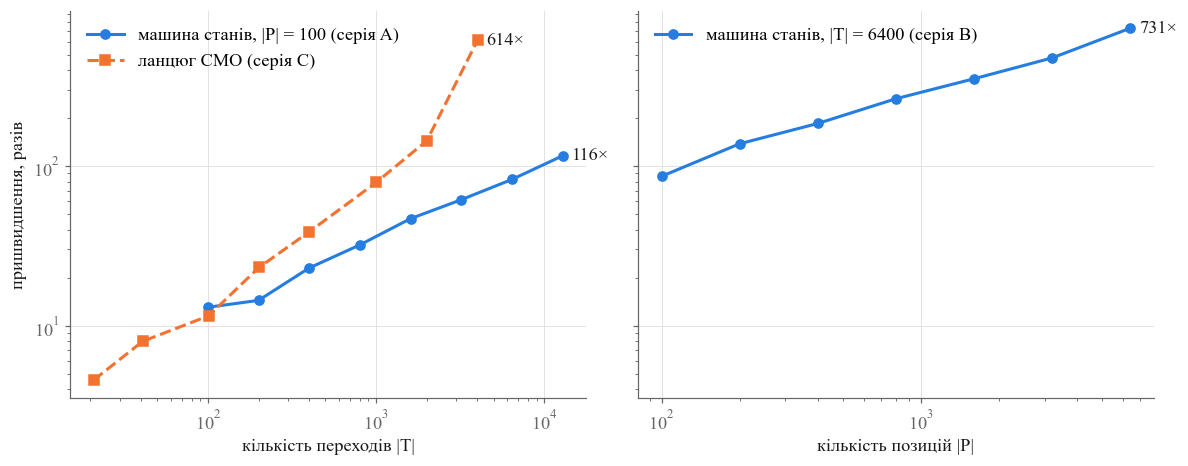

,series,transitions,speedup,places
0,A,100.0,13.0,NaN
1,A,200.0,14.4,NaN
2,A,400.0,23.0,NaN
3,A,800.0,32.0,NaN
4,A,1600.0,46.8,NaN
5,A,3200.0,61.5,NaN
6,A,6400.0,82.4,NaN
7,A,12800.0,115.9,NaN
8,C,21.0,4.6,NaN
9,C,41.0,8.0,NaN


In [5]:
speedup_rows = []
fig, (by_t, by_p) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for i, (name, title) in enumerate([("A", "машина станів, |P| = 100 (серія A)"), ("C", "ланцюг СМО (серія C)")]):
    data = summaries[name].pivot_table(index="transitions", columns="finder", values="median_ns_per_tick")
    ratio = data["naive"] / data["incremental"]
    for t, r in ratio.items():
        speedup_rows.append(dict(series=name, transitions=t, speedup=r))
    by_t.plot(ratio.index, ratio.values, color=SLOTS[i], marker=MARKERS[i], linestyle=LINES[i], label=title)
    by_t.annotate(f"{ratio.values[-1]:.0f}×", (ratio.index[-1], ratio.values[-1]), textcoords="offset points",
                  xytext=(6, 0), va="center", color="#191919")
data = summaries["B"].pivot_table(index="places", columns="finder", values="median_ns_per_tick")
ratio = data["naive"] / data["incremental"]
for p, r in ratio.items():
    speedup_rows.append(dict(series="B", places=p, speedup=r))
by_p.plot(ratio.index, ratio.values, color=SLOTS[0], marker=MARKERS[0], linestyle=LINES[0],
          label="машина станів, |T| = 6400 (серія B)")
by_p.annotate(f"{ratio.values[-1]:.0f}×", (ratio.index[-1], ratio.values[-1]), textcoords="offset points",
              xytext=(6, 0), va="center", color="#191919")
for ax, xlabel in [(by_t, "кількість переходів |T|"), (by_p, "кількість позицій |P|")]:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.legend(loc="upper left")
by_t.set_ylabel("пришвидшення, разів")
fig.tight_layout()
save(fig, "4.2-speedup")
plt.show()
speedup = pd.DataFrame(speedup_rows)
speedup.to_csv(TABLES / "4.2-speedup.csv", index=False)
speedup.round(1)

## 4.3 Множина досяжних маркірувань

Кожна мережа імітувалася до насичення (100 запусків поспіль без нових маркірувань, T = 1000 тактів на запуск)
і порівнювалася з деревом досяжності. Головні величини: частка маркірувань дерева, знайдених імітацією, і кількість
запусків до насичення - залежно від розміру множини досяжних маркірувань.

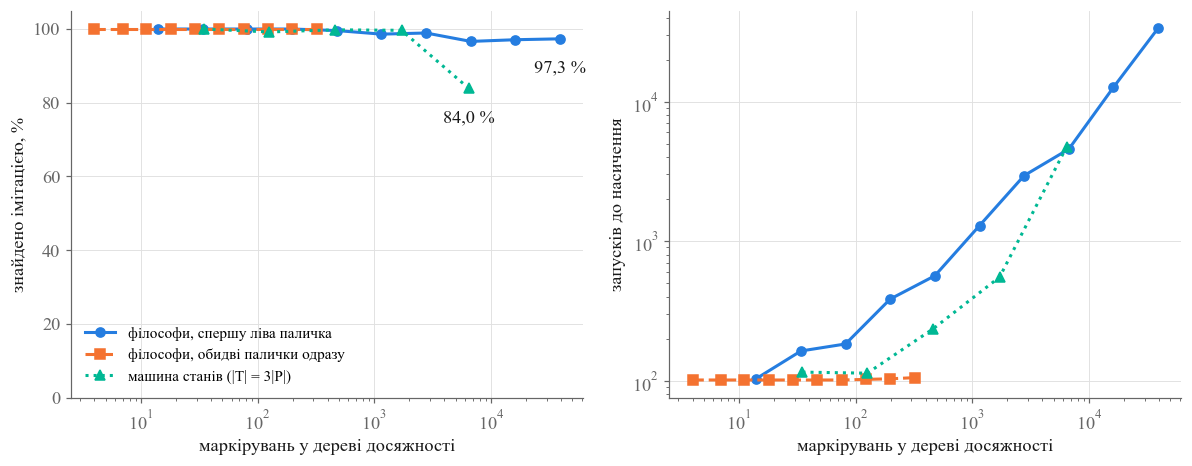

,net,places,transitions,tree_markings,met_in_tree,found_share,runs,seconds
0,philosophers-3,12,9,14,14,1.000,103,0.003
1,philosophers-3-both-at-once,9,6,4,4,1.000,101,0.035
2,philosophers-4,16,12,34,34,1.000,163,0.003
3,philosophers-4-both-at-once,12,8,7,7,1.000,101,0.038
4,philosophers-5,20,15,82,82,1.000,183,0.005
5,philosophers-5-both-at-once,15,10,11,11,1.000,101,0.043
6,philosophers-6,24,18,198,198,1.000,384,0.009
7,philosophers-6-both-at-once,18,12,18,18,1.000,101,0.035
8,philosophers-7,28,21,478,476,0.996,564,0.013
9,philosophers-7-both-at-once,21,14,29,29,1.000,101,0.043


In [6]:
reach = pd.read_csv(RESULTS / "4.3-reachability" / "summary.csv")
reach["found_share"] = reach["met_in_tree"] / reach["tree_markings"]


def family(net):
    if net.startswith("state-machine"):
        return "машина станів (|T| = 3|P|)"
    return "філософи, обидві палички одразу" if net.endswith("both-at-once") else "філософи, спершу ліва паличка"


reach["family"] = reach["net"].map(family)
FAMILIES = ["філософи, спершу ліва паличка", "філософи, обидві палички одразу", "машина станів (|T| = 3|P|)"]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.4))
for i, name in enumerate(FAMILIES):
    part = reach[reach["family"] == name].sort_values("tree_markings")
    style = dict(color=SLOTS[i], marker=MARKERS[i], linestyle=LINES[i], label=name)
    left.plot(part["tree_markings"], 100 * part["found_share"], **style)
    right.plot(part["tree_markings"], part["runs"], **style)
    last = part.iloc[-1]
    if last["found_share"] < 1:
        left.annotate(f"{100 * last['found_share']:.1f} %".replace(".", ","),
                      (last["tree_markings"], 100 * last["found_share"]), textcoords="offset points",
                      xytext=(0, -14), ha="center", va="top", color="#191919")
left.set_ylim(0, 105)
left.set_xscale("log")
left.set_xlabel("маркірувань у дереві досяжності")
left.set_ylabel("знайдено імітацією, %")
right.set_xscale("log")
right.set_yscale("log")
right.set_xlabel("маркірувань у дереві досяжності")
right.set_ylabel("запусків до насичення")
left.legend(fontsize=10)
fig.tight_layout()
save(fig, "4.3-found-and-runs")
plt.show()

reach.to_csv(TABLES / "4.3-reachability.csv", index=False)
reach[["net", "places", "transitions", "tree_markings", "met_in_tree", "found_share", "runs", "seconds"]].round(3)

Висновки (за таблицею вище):

* для малих мереж (до кількох сотень маркірувань) імітація знаходить усю множину досяжних маркірувань;
* зі зростанням мережі частка знайденого падає: 97,3 % для 12 філософів (39 202 маркірування), 84 % для машини
  станів P = 8 (6435 маркірувань). Критерій насичення спрацьовує, хоча частина маркірувань не знайдена: вони
  малоймовірні (у машині станів - стани, де багато маркерів зібралося в позиціях з малою кількістю вхідних переходів).
  Межа q* обмежує ймовірність того, що *наступний запуск* знайде нове маркірування, а не частку пропущених;
* кількість запусків до насичення росте разом із розміром множини: від ≈ 100 до 33 534 для 12 філософів;
* у філософів «обидві палички одразу» множина мала (≤ 322) і рівномірно відвідувана - повністю знаходиться
  за ≈ 100 запусків.

### Криві насичення

Накопичена частка маркірувань дерева залежно від номера запуску; маркер - момент зупинки за критерієм насичення з підсумковою часткою
(100 запусків поспіль без нових маркірувань). Пологий «хвіст» - це запуски, які вже не знаходять нового: критерій
зупиняє серію, хоча рідкісні маркірування ще не знайдені.

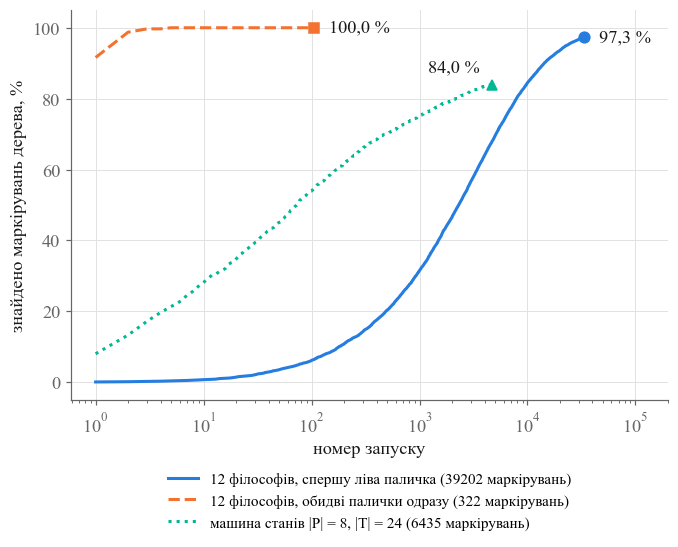

In [7]:
CURVES = {
    "philosophers-12": ("12 філософів, спершу ліва паличка", dict(xytext=(10, 0), ha="left", va="center")),
    "philosophers-12-both-at-once": ("12 філософів, обидві палички одразу", dict(xytext=(10, 0), ha="left", va="center")),
    "state-machine-8": ("машина станів |P| = 8, |T| = 24", dict(xytext=(-8, 6), ha="right", va="bottom")),
}
fig, ax = plt.subplots(figsize=(7, 4.6))
for i, (net, (title, place)) in enumerate(CURVES.items()):
    curve = pd.read_csv(RESULTS / "4.3-reachability" / net / "saturation.csv")
    tree = reach.loc[reach["net"] == net, "tree_markings"].iloc[0]
    runs, share = curve["run"].to_numpy() + 1, 100 * curve["total_markings"].to_numpy() / tree
    ax.plot(runs, share, color=SLOTS[i], linestyle=LINES[i], label=f"{title} ({tree} маркірувань)")
    ax.plot(runs[-1], share[-1], color=SLOTS[i], marker=MARKERS[i], markersize=7)
    ax.annotate(f"{share[-1]:.1f} %".replace(".", ","), (runs[-1], share[-1]),
                textcoords="offset points", color="#191919", **place)
ax.set_xscale("log")
ax.set_xlim(right=2e5)
ax.set_xlabel("номер запуску")
ax.set_ylabel("знайдено маркірувань дерева, %")
ax.legend(fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.15))
save(fig, "4.3-saturation")
plt.show()

## 4.4 Активність переходів

N = 2000 запусків (за Чебишевим для часток: σ² ≤ 0,25, ε = 0,05, β = 0,95), T = 1000 тактів.
Для кожної мережі: скільки переходів спрацювали хоча б раз (рівень ≥ 1), скільки жодного разу (рівень 0, з межею
ймовірності q*), найменша й найбільша частка запусків зі спрацюванням і чи виключено рівень 4 (були запуски з тупиком).

In [8]:
activity_rows = []
for directory in sorted((RESULTS / "4.4-activity").iterdir()):
    if directory.name == "nets":
        continue
    data = pd.read_csv(directory / "activity.csv")
    text = (directory / "activity.txt").read_text()
    level4 = re.search(r"Level 4: excluded for every transition, (\d+) of (\d+) runs", text)
    activity_rows.append(dict(
        net=directory.name, transitions=len(data), runs=data["runs"].iloc[0],
        fired=(data["level"] == ">=1").sum(), never_fired=(data["level"] == "0").sum(),
        min_share=data["share"].min(), max_share=data["share"].max(),
        least_active=data.loc[data["share"].idxmin(), "transition"],
        deadlock_runs=int(level4.group(1)) if level4 else 0,
        level4_excluded=level4 is not None,
        dead_bound=data["fire_probability_bound"].dropna().max() if data["fire_probability_bound"].notna().any() else None,
    ))
activity = pd.DataFrame(activity_rows)
activity.to_csv(TABLES / "4.4-activity.csv", index=False)
activity.round(4)

,net,transitions,runs,fired,never_fired,min_share,max_share,least_active,deadlock_runs,level4_excluded,dead_bound
0,dead-transition,2,2000,1,1,0.0000,1.0,Never,2000,True,0.0015
1,philosophers-10,30,2000,30,0,0.4650,1.0,TakeRight5,2000,True,NaN
2,philosophers-10-both-at-once,20,2000,20,0,1.0000,1.0,Take1,0,False,NaN
3,philosophers-12,36,2000,36,0,0.4520,1.0,TakeRight5,2000,True,NaN
4,philosophers-12-both-at-once,24,2000,24,0,1.0000,1.0,Take1,0,False,NaN
5,philosophers-5,15,2000,15,0,0.4395,1.0,TakeRight1,2000,True,NaN
6,philosophers-5-both-at-once,10,2000,10,0,1.0000,1.0,Take1,0,False,NaN
7,queue-chain-2,5,2000,5,0,1.0000,1.0,Arrival,0,False,NaN
8,state-machine-8,24,2000,24,0,0.9910,1.0,T9,0,False,NaN


## 3.7 Верифікація: зведення

Для кожної мережі верифікації - порівняння з деревом досяжності (еталон) і середні маркірування з похибкою.
Очікувані значення ручного розрахунку - у `EXPECTED.md`; тут лише зведення отриманих.

In [9]:
def read_markings(path):
    data = pd.read_csv(path)
    places = [c for c in data.columns if c not in ("id", "terminal")]
    rows = data[places].to_numpy(float)
    return [tuple(r) for r in rows], [tuple(r) for r in data.loc[data["terminal"], places].to_numpy(float)]


def covered(marking, by):
    return any(all(a <= b for a, b in zip(marking, other)) for other in by)


verification_rows = []
means_rows = []
VERIFICATION = RESULTS / "verification"
for directory in sorted(p for p in VERIFICATION.iterdir() if p.is_dir() and p.name != "nets"):
    tree, tree_dead = read_markings(directory / "tree" / "reachable-markings.csv")
    met, met_dead = read_markings(directory / "simulated-reachability" / "reachable-markings.csv")
    tree_set = set(tree)
    runs = pd.read_csv(directory / "series" / "runs.csv")
    n = len(runs)
    deadlock = runs["deadlock"].astype(bool)
    p = deadlock.mean()
    dead_tree = pd.read_csv(directory / "tree" / "dead-transitions.csv")
    act = pd.read_csv(directory / "activity" / "activity.csv")
    verification_rows.append(dict(
        net=directory.name, tree_markings=len(tree), met=len(met), met_in_tree=sum(m in tree_set for m in met),
        not_covered=sum(not covered(m, tree) for m in met), tree_deadlocks=len(tree_dead),
        deadlocks_met=len(set(met_dead) & set(tree_dead)),
        dead_in_tree=", ".join(dead_tree.loc[dead_tree["dead"], "transition"]) or "-",
        never_fired=", ".join(act.loc[act["level"] == "0", "transition"]) or "-",
        series_runs=n, deadlock_share=p, deadlock_share_error=chebyshev_error(p * (1 - p), n) if n else np.nan,
        mean_deadlock_tick=runs.loc[deadlock, "ticks"].mean() if deadlock.any() else np.nan,
        mean_deadlock_tick_error=chebyshev_error(runs.loc[deadlock, "ticks"].var(), deadlock.sum())
        if deadlock.sum() > 1 else np.nan,
    ))
    stats = pd.read_csv(directory / "series" / "place-statistics.csv")
    stats.insert(0, "net", directory.name)
    means_rows.append(stats)

verification = pd.DataFrame(verification_rows)
verification.to_csv(TABLES / "verification-summary.csv", index=False)
means = pd.concat(means_rows, ignore_index=True)
means.to_csv(TABLES / "verification-means.csv", index=False)
verification.round(4)

,net,tree_markings,met,met_in_tree,not_covered,tree_deadlocks,deadlocks_met,dead_in_tree,never_fired,series_runs,deadlock_share,deadlock_share_error,mean_deadlock_tick,mean_deadlock_tick_error
0,conflict-chain,5,5,5,0,2,2,-,-,506,1.0,0.0,1.6304,0.0961
1,dead-transition,2,2,2,0,1,1,Never,Never,20,1.0,0.0,1.0000,0.0000
2,lecture7-abc,6,6,6,0,2,2,-,-,716,1.0,0.0,2.7444,0.0730
3,partial-resource,7,7,7,0,1,1,-,-,20,1.0,0.0,6.0000,0.0000
4,philosophers-3,14,14,14,0,1,1,-,-,361,1.0,0.0,9.6316,1.8209
5,philosophers-4,34,34,34,0,1,1,-,-,503,1.0,0.0,11.9980,1.8132
6,philosophers-5,82,82,82,0,1,1,-,-,560,1.0,0.0,14.7446,1.9488
7,philosophers-5-both-at-once,11,11,11,0,0,0,-,-,20,0.0,0.0,NaN,NaN
8,queue-chain-2,11,11,11,0,0,0,-,-,10000,0.0,0.0,NaN,NaN
9,shared-resource,7,7,7,0,1,1,-,-,20,1.0,0.0,6.0000,0.0000


### Обідні філософи: ймовірність тупику і такт тупику

Ймовірність тупику за T = 1000 тактів і середній такт його настання (з похибкою за Чебишевим) - лише у верифікації,
як і заплановано.

In [10]:
verification[verification["net"].str.startswith("philosophers")][
    ["net", "series_runs", "deadlock_share", "deadlock_share_error", "mean_deadlock_tick", "mean_deadlock_tick_error"]
].round(3)

,net,series_runs,deadlock_share,deadlock_share_error,mean_deadlock_tick,mean_deadlock_tick_error
4,philosophers-3,361,1.0,0.0,9.632,1.821
5,philosophers-4,503,1.0,0.0,11.998,1.813
6,philosophers-5,560,1.0,0.0,14.745,1.949
7,philosophers-5-both-at-once,20,0.0,0.0,NaN,NaN


In [11]:
means[means["net"].isin(["lecture7-abc", "shared-resource", "partial-resource", "conflict-chain", "dead-transition"])][
    ["net", "place", "mean", "error", "min", "max", "runs"]
].round(4)

,net,place,mean,error,min,max,runs
0,conflict-chain,A,0.5056,0.0263,0,1,506
1,conflict-chain,B,0.4944,0.0263,0,1,506
2,conflict-chain,X,0.8152,0.0480,0,2,506
3,dead-transition,P,0.5000,0.0000,0,1,20
4,dead-transition,Q,0.5000,0.0000,0,1,20
5,lecture7-abc,P1,0.3946,0.0181,0,1,716
6,lecture7-abc,P2,0.7535,0.0418,0,2,716
7,lecture7-abc,P3,0.6816,0.0689,0,2,716
8,lecture7-abc,P4,0.0852,0.0243,0,1,716
9,partial-resource,Jobs,1.2857,0.0000,0,3,20


## 5.2 Пропозиція: інкрементальний пошук у серіях запусків

Пробний запуск пропозиції (`petri experiments proposal`): ті самі серії, що в 3.7, 4.3 і 4.4, на мережах з десятками, сотнями
і тисячами переходів, з перебором та з інкрементальним пошуком. Кожна серія спершу виконується один раз без заміру (прогрів
JIT-компілятора на тому самому коді), потім вимірюється 20 разів; значення - медіана, як і в 4.2.
Процес закріплено на продуктивних ядрах процесора (`taskset -c 0-7`): без цього потік переходив на енергоефективні
ядра, і час однакових серій відрізнявся вдвічі. Серії: середні маркірування (500 запусків), множина досяжних маркірувань
(100 запусків), активність (2000 запусків); T = 1000 тактів, s = 1.

Пришвидшення = медіана часу серії перебором / медіана часу серії з інкрементальним пошуком. Стовпчик `result` показує,
що обидва способи дають близькі результати: найбільше середнє маркірування, кількість знайдених маркірувань і найменшу
частку запусків.

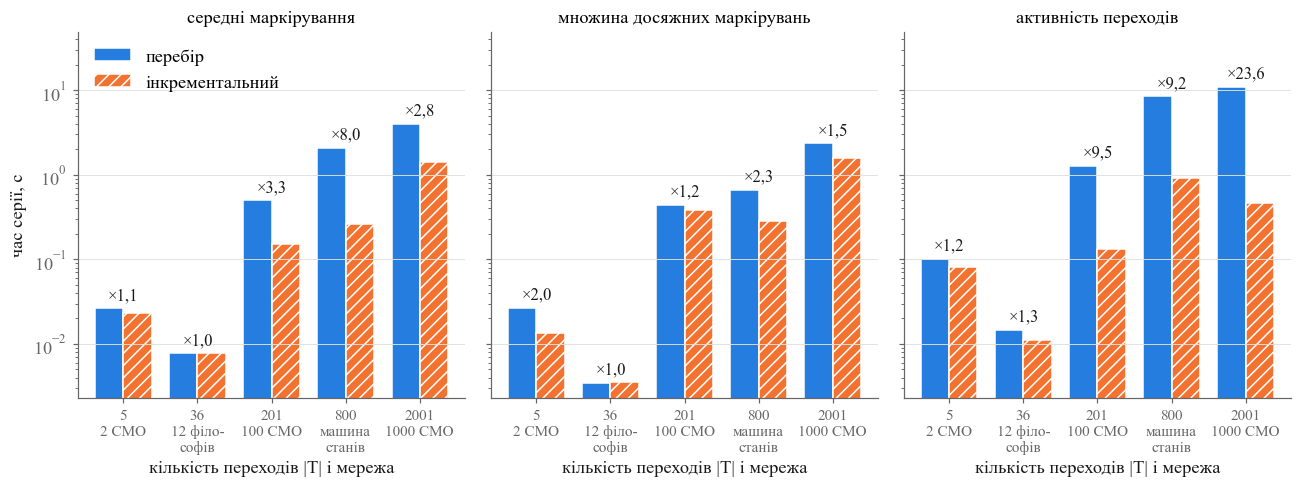

,series,net,places,transitions,naive,incremental,speedup
3,activity,queue-chain-2,8,5,0.102,0.082,1.246
0,activity,philosophers-12,48,36,0.015,0.011,1.333
1,activity,queue-chain-100,302,201,1.275,0.134,9.503
4,activity,state-machine-100-800,100,800,8.430,0.919,9.177
2,activity,queue-chain-1000,3002,2001,10.936,0.463,23.604
8,means,queue-chain-2,8,5,0.026,0.023,1.136
5,means,philosophers-12,48,36,0.008,0.008,1.006
6,means,queue-chain-100,302,201,0.499,0.151,3.306
9,means,state-machine-100-800,100,800,2.088,0.260,8.026
7,means,queue-chain-1000,3002,2001,4.022,1.412,2.849


finder                              incremental       naive
series       net                                           
activity     philosophers-12             0.4605      0.4520
             queue-chain-100             0.0000      0.0000
             queue-chain-1000            0.0000      0.0000
             queue-chain-2               1.0000      1.0000
             state-machine-100-800       0.3135      0.3020
means        philosophers-12             0.5587      0.5595
             queue-chain-100            26.6844     26.4682
             queue-chain-1000           26.6844     26.4682
             queue-chain-2              87.3489     87.3713
             state-machine-100-800       4.3397      4.5682
reachability philosophers-12          2249.0000   2427.0000
             queue-chain-100         80959.0000  80902.0000
             queue-chain-1000        80959.0000  80902.0000
             queue-chain-2              11.0000     11.0000
             state-machine-100-800   99962.0000  99955.0000

In [12]:
proposal = pd.read_csv(RESULTS / "5.2-proposal" / "summary.csv")
NET_LABELS = {
    "queue-chain-2": "2 СМО",
    "philosophers-12": "12 філо-\nсофів",
    "queue-chain-100": "100 СМО",
    "state-machine-100-800": "машина\nстанів",
    "queue-chain-1000": "1000 СМО",
}
SERIES_TITLES = {"means": "середні маркірування", "reachability": "множина досяжних маркірувань",
                 "activity": "активність переходів"}

times = proposal.pivot_table(index=["series", "net"], columns="finder", values="seconds").reset_index()
times["speedup"] = times["naive"] / times["incremental"]
sizes = proposal.drop_duplicates("net").set_index("net")[["places", "transitions"]]
times = times.join(sizes, on="net").sort_values(["series", "transitions"])
results = proposal.pivot_table(index=["series", "net"], columns="finder", values="result")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True)
width = 0.38
for ax, (series, title) in zip(axes, SERIES_TITLES.items()):
    data = times[times["series"] == series].set_index("net").loc[list(NET_LABELS)]
    x = np.arange(len(data))
    ax.bar(x - width / 2, data["naive"], width, color=STYLE["naive"]["color"], edgecolor="white", linewidth=1,
           label="перебір")
    ax.bar(x + width / 2, data["incremental"], width, color=STYLE["incremental"]["color"], edgecolor="white",
           linewidth=1, hatch="///", label="інкрементальний")
    for xi, (_, row) in zip(x, data.iterrows()):
        top = max(row["naive"], row["incremental"])
        ax.annotate(f"×{row['speedup']:.1f}".replace(".", ","), (xi, top), textcoords="offset points",
                    xytext=(0, 3), ha="center", va="bottom", fontsize=11, color="#191919")
    ax.set_yscale("log")
    ax.set_xticks(x, [f"{t}\n{NET_LABELS[n]}" for n, t in zip(data.index, data["transitions"])], fontsize=10)
    ax.set_xlabel("кількість переходів |T| і мережа")
    ax.set_title(title, fontsize=12)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("час серії, с")
axes[0].legend(loc="upper left")
low, high = axes[0].get_ylim()
axes[0].set_ylim(low, high * 3)
fig.tight_layout()
save(fig, "5.2-proposal")
plt.show()

table = times[["series", "net", "places", "transitions", "naive", "incremental", "speedup"]]
table.to_csv(TABLES / "5.2-proposal.csv", index=False)
display(table.round(3))
results.round(4)

Висновки (за рисунком і таблицею вище):

* серія активності (спостерігач лише рахує спрацювання) пришвидшується найбільше: 9,5× (|T| = 201), 9,2× (800), 23,6× (2001);
* серія середніх - 2,9-8,0× на великих мережах: спостерігач щотакту оновлює статистику всіх |P| позицій;
* серія множини досяжних маркірувань - лише 1,2-2,3×: час займають копіювання маркірування і правило ω;
* на мережах з 5 і 36 переходами серії тривають мілісекунди, і помітного виграшу немає;
* пришвидшення менші, ніж у 4.2 (до 731×), бо там вимірювався лише такт без спостерігачів.
